In [ ]:

# CHAPTER 1 : ENVIRONMENT SETUP
# Cat vs Dog Classification using CNN


# File & Folder Operations
import os

# Numerical Computing
import numpy as np

# Data Manipulation
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Image Processing
from PIL import Image
import cv2

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import models

# Dataset Generator
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Model Evaluation
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

In [ ]:
print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("Pandas     :", pd.__version__)

In [ ]:
print(tf.config.list_physical_devices())

In [ ]:
import os
import shutil

# Source folder (mixed images)
source_folder = "cat_dog"

# Destination folders
cat_folder = os.path.join("dataset", "Cat")
dog_folder = os.path.join("dataset", "Dog")

# Create folders if they don't exist
os.makedirs(cat_folder, exist_ok=True)
os.makedirs(dog_folder, exist_ok=True)

# Move images into respective folders
for file in os.listdir(source_folder):

    source_path = os.path.join(source_folder, file)

    if file.startswith("cat"):
        shutil.copy2(source_path, cat_folder)

    elif file.startswith("dog"):
        shutil.copy2(source_path, dog_folder)

print("Dataset organized successfully!")

Cats : 12500
Dogs : 12500


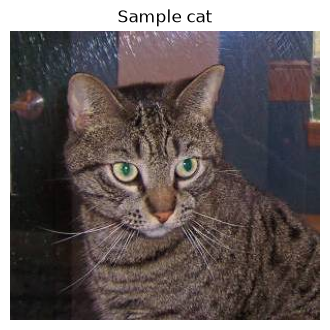

Type : <class 'numpy.ndarray'>
Shape : (280, 300, 3)
PIL Size : (300, 280)
Pixel Value : [70 68 81]


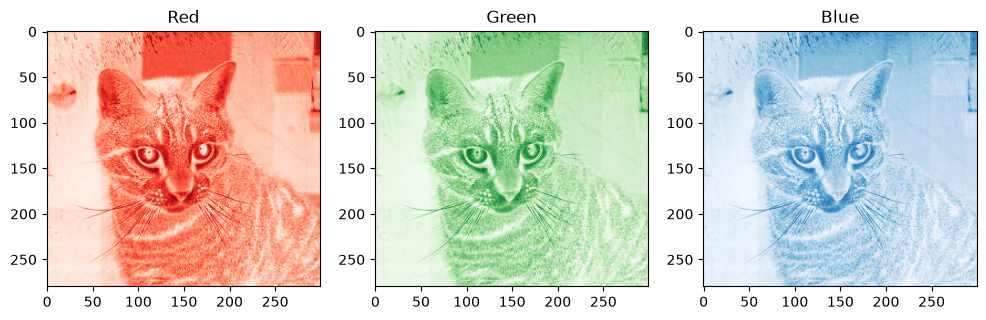

In [5]:
# ==========================================
# CHAPTER 2 : LOADING THE DATASET
# ==========================================

#Dataset Path
dataset_path = "dataset"

cat_path = os.path.join(dataset_path, "Cat")
dog_path = os.path.join(dataset_path, "Dog")

#count images
cat_images = os.listdir("dataset/Cat")
dog_images = os.listdir("dataset/Dog")

print("Cats :", len(cat_images))
print("Dogs :", len(dog_images))

# Read one cat image
img = Image.open(os.path.join(cat_path, cat_images[1]))

#Diaplay
plt.figure(figsize=(4,4))
plt.imshow(img)
plt.title("Sample cat")
plt.axis("off")
plt.show()

# Convert to NumPy
image_array = np.array(img)

print("Type :", type(image_array))
print("Shape :", image_array.shape)
print("PIL Size :", img.size)

# RGB value of one pixel
print("Pixel Value :", image_array[50,100])

# Display RGB channels
red = image_array[:,:,0]
green = image_array[:,:,1]
blue = image_array[:,:,2]

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(red, cmap="Reds")
plt.title("Red")

plt.subplot(1,3,2)
plt.imshow(green, cmap="Greens")
plt.title("Green")

plt.subplot(1,3,3)
plt.imshow(blue, cmap="Blues")
plt.title("Blue")

plt.show()

Found 20000 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.
{'Cat': 0, 'Dog': 1}
(32, 128, 128, 3)
(32,)


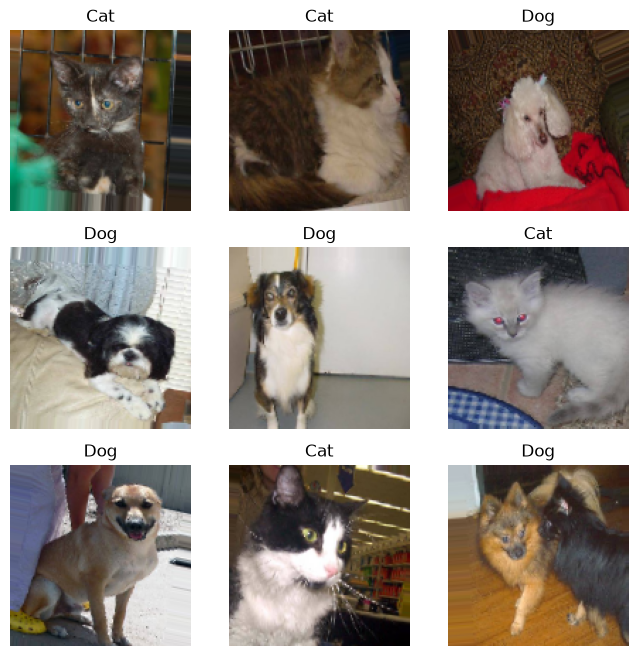

In [11]:
# ==========================================
# CHAPTER 3 : IMAGE PREPROCESSING
# ==========================================

# Image size
IMG_HEIGHT = 128
IMG_WIDTH = 128
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

#Batch size
BATCH_SIZE = 32

#Generator
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    horizontal_flip=True,
    validation_split=0.20
)

# Training data
train_generator = train_datagen.flow_from_directory(
    directory="dataset",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    shuffle=True
)

# Validation data
validation_generator = train_datagen.flow_from_directory(
    directory="dataset",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False
)

# Class mapping
print(train_generator.class_indices)

# One batch
images, labels= next(train_generator)

print(images.shape)
print(labels.shape)

# Display sample images
plt.figure(figsize=(8,8))

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    label = "Dog" if labels[i] == 1 else "Cat"
    plt.title(label)
    plt.axis("off")
plt.show()

In [12]:
# ==========================================
# CHAPTER 4 : CNN MODEL
# ==========================================

model = models.Sequential([

    #Input layer
    layers.Input(shape=(128,128,3)),

    #Convolutional Block
    layers.Conv2D(filters=32, kernel_size=(3,3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2,2)),

    #Convolutional block2 
    layers.Conv2D(64, (3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),

    #Conver 2D -> 1D
    layers.Flatten(),

    #Fully connected layer
    layers.Dense(128, activation="relu"),

    #Prevent overfitting
    layers.Dropout(0.6),

    #Output layer
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,449 (28.20 MB)

 Trainable params: 7,392,449 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# ==========================================
# CHAPTER 5 : MODEL COMPILATION & TRAINING
# ==========================================
from tensorflow.keras.callbacks import EarlyStopping

# Compile Model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,
    callbacks=[early_stop]
)

# Check Stored Metrics
print(history.history.keys())

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 280s 441ms/step - accuracy: 0.5841 - loss: 0.6852 - val_accuracy: 0.6498 - val_loss: 0.6334
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 253s 405ms/step - accuracy: 0.6531 - loss: 0.6326 - val_accuracy: 0.6824 - val_loss: 0.5995
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3975s 6s/step - accuracy: 0.6862 - loss: 0.5921 - val_accuracy: 0.6670 - val_loss: 0.6078
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 688s 1s/step - accuracy: 0.7189 - loss: 0.5600 - val_accuracy: 0.6952 - val_loss: 0.5616
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 457s 729ms/step - accuracy: 0.7379 - loss: 0.5248 - val_accuracy: 0.7522 - val_loss: 0.4970
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 651s 1s/step - accuracy: 0.7548 - loss: 0.5027 - val_accuracy: 0.7830 - val_loss: 0.4613
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 801s 1s/step - accuracy: 0.7682 - loss: 0.4905 - val_accuracy: 0.7808 - val_loss: 0.4643
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 1005s 2s/step - accuracy: 0.7775 - loss: 0.4738

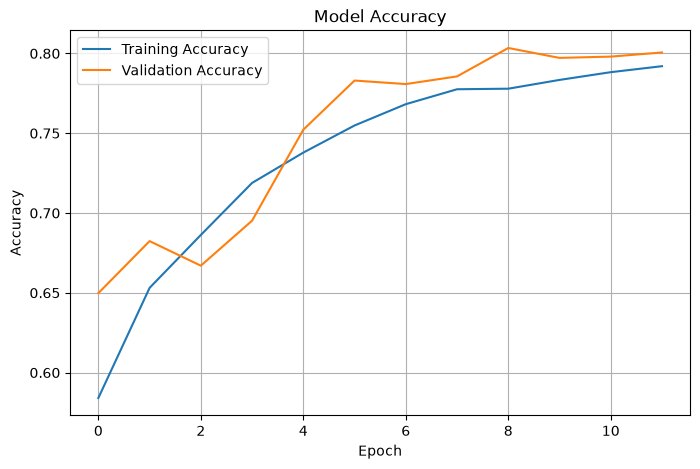

In [14]:
# ==========================================
# CHAPTER 6 : TRAINING VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")

plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

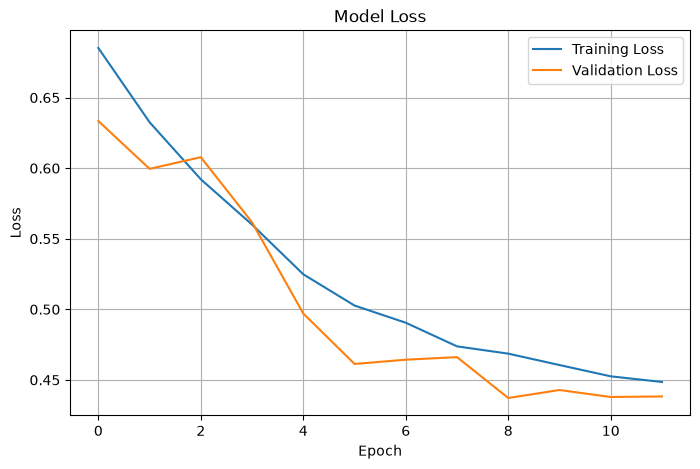

In [15]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

In [16]:
# Predict probabilities

predictions = model.predict(validation_generator)

print(predictions.shape)

157/157 ━━━━━━━━━━━━━━━━━━━━ 102s 647ms/step
(5000, 1)


In [17]:
print(predictions[:5])

[[0.531908  ]
 [0.04421982]
 [0.3866109 ]
 [0.79226315]
 [0.26548737]]


In [18]:
predicted_labels = (predictions > 0.5).astype(int)

print(predicted_labels[:5])

[[1]
 [0]
 [0]
 [1]
 [0]]


In [19]:
true_labels = validation_generator.classes

print(true_labels[:5])

[0 0 0 0 0]


In [20]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(true_labels, predicted_labels)

print(cm)

[[1887  613]
 [ 419 2081]]


In [ ]:
import seaborn as sns

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Cat","Dog"],
    yticklabels=["Cat","Dog"]
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=["Cat","Dog"]
    )
)

In [ ]:
images, labels = next(validation_generator)

pred = model.predict(images)

plt.figure(figsize=(10,10))

for i in range(9):

    plt.subplot(3,3,i+1)

    plt.imshow(images[i])

    predicted = "Dog" if pred[i] > 0.5 else "Cat"

    actual = "Dog" if labels[i] == 1 else "Cat"

    plt.title(f"P:{predicted}\nA:{actual}")

    plt.axis("off")

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================
# CHAPTER 7 : CUSTOM IMAGE INFERENCE
# ==========================================

from tensorflow.keras.utils import load_img, img_to_array

def predict_image(image_path, model):

    image = load_img(
        image_path,
        target_size=(128,128)
    )
    plt.imshow(image)
    plt.axis("off")

    image_array = img_to_array(image)

    image_array = image_array / 255.0

    image_array = np.expand_dims(image_array, axis=0)

    print(image_array.shape)

    prediction = model.predict(image_array, verbose=0)

    probability = prediction[0][0]

    if probability > 0.5 :

        label = "Dog"

        confidence = probability * 100

    else:
        label = "Cat"

        confidence = (1 - probability) * 100

    plt.title(f"{label} ({confidence:2f}%)")
    plt.show()

    return label, confidence

#Example
label, confidence = predict_image("test_images/image_name.jpg", model)
print(label)
print(confidence)

In [ ]:
# ==========================================
# CHAPTER 8 : MODEL SAVING & LOADING
# ==========================================

# ---------- Save Model ----------

model.save("models/cat_dog_cnn.keras")

print("Model saved successfully.")

# ---------- Lode Model ----------
from tensorflow.keras.models import load_model

loaded_model = load_model("models/cat_dog_cnn.keras")

print("Model loaded successfully.")

# ---------- Verify ----------
loaded_model.summary()

# ---------- Predict ----------
label,  confidence = predict_image(
    "test_images/my_pet.jpg",
    loaded_model
)

print(label)
print(f"Confidence : {confidence:.2f}%")